# Zachary Weed

In [171]:
import networkx as nx
import numpy as np
import tensorflow as tf
import random
import torch.nn.functional as F
import torch

from torch.utils.data import Dataset, DataLoader
from itertools import combinations
from torch.nn.parameter import Parameter

# [Problem 1] - Building a Graph with NetworkX

**Problem 1.** Consider the small directed graph below with 5 nodes. Build that graph node by node and edge by edge, using NetworkX API. Determine and print teh adjacency matrix of the graph using NetworkX API. Assign a different color to every node. Treat node color as its feature. Create note label (features) matrix as one hot encoded representations of node colors. Plot resulting graph, including node (numerical) labels and colors with the help of NetworkX API.



Adjacency Matrix:
[[0. 1. 1. 0. 0. 0. 0.]
 [1. 0. 1. 0. 1. 1. 0.]
 [1. 1. 0. 1. 1. 1. 0.]
 [0. 0. 1. 0. 0. 0. 0.]
 [0. 1. 1. 0. 0. 0. 0.]
 [0. 1. 1. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0.]]




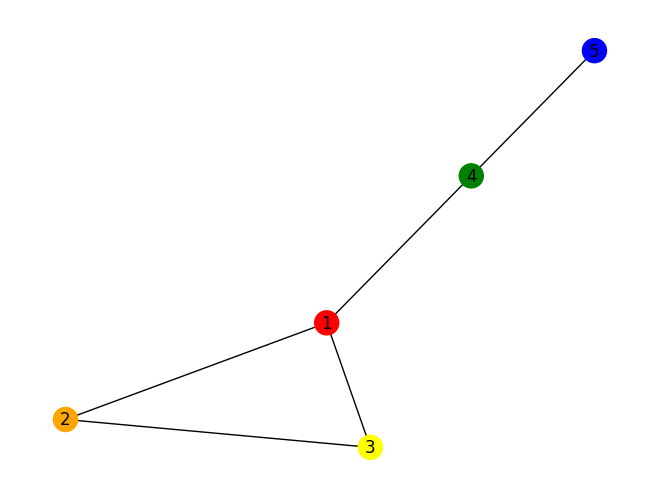

In [204]:
colors = [
    'red',
    'orange',
    'yellow',
    'green',
    'blue'
]
nodes = [1, 2, 3, 4, 5]

#########################
#     Builds Graph      #
#########################
G = nx.Graph()
G.add_nodes_from(nodes)
G.add_edges_from([(1,2), (1,3), (3, 2), (4, 1), (4,5)])
##########################
#   End Builds Graph     #
##########################

###########################
# Builds Adjacency Matrix #
###########################
print("\n")

def adjacency_matrix(g):
    return nx.to_numpy_array(g, nodelist = g.nodes())

am = adjacency_matrix(g)
print("Adjacency Matrix:")
with np.printoptions(threshold = np.inf):
    print(adjacency_matrix(g))

print("\n")
############################
#  Ends Adjacency Matrix   #
############################

##########################
#   Builds Feature Map   #
##########################
number_of_nodes = len(nodes)
number_of_colors = len(colors)

feature_map = np.zeros((number_of_nodes, number_of_colors))

for i, color in enumerate(colors):
    # flips bit for a given color
    feature_map[i, colors.index(color)] = 1
###########################
#     End Feature Map     #
###########################

##########
#  Plots #
##########

nx.draw(G, node_color = colors, with_labels = True, edge_color = 'black', arrows = True)

#############
# Ends Plot #
#############

# [Problem 2] - Build Permutation of Matrix 

**Problem 2.** Create a permutation matrix P that will permute nodes of the graph in Problem 1 from (1, 2, 3, 4, 5) to (5, 1, 3, 2, 4). That matrix is relabeling nodes. Express adjacency matrix for the permuted graph over the adjecancy matrix for the original graph and the permutation matrix. Perform various matrix multiplications using torch API. Is the adjaency matrix of the permuted graph identical to the one in problem 1.

Something I had to do some research on here is that the question originally did not make sense because it seemed like the graph did not technically have any inherent ordering. After incorporating the adjacency matrix, we can see that while the structure is the same, order does impact adjacency matrices. In other words, it is **not** identical.

In [80]:
# Defines a permutation map, assigning 
# each integer to another position
permutation = { 1: 5, 2:1, 3:3, 4:2, 5:4 }
permuted = nx.relabel_nodes(G, permutation)

In [81]:
# Building an adjacency matrix
adjacency_matrix = nx.to_numpy_array(permuted, nodelist = G.nodes())

In [82]:
# Performing matrix 
# Multiplication of the graph

a = adjacency_matrix[0:2]
b = tf.transpose(adjacency_matrix[3:])
c = tf.matmul(a, b)

print(c)

tf.Tensor(
[[0. 1.]
 [0. 0.]], shape=(2, 2), dtype=float64)


# [Problem 3] - Calculating Weights of Graphs in NetworkX

**Problem 3.** Assign weights { w_i = (i - j)^2 } to all edges {i,j} of the graphs in Problem 1. Make that assignment using NetworkX API. Write function f() which calculates the average weight of nodes in the graph. Apply that function through NetworkX API. Record the average weight. Calculate the average weight of the permuted graph of Problem 2. What is the result? Is function f() permutation invariant or permutation equivariant?

In [83]:
# Visualizing edges
print(G.edges())

[(1, 2), (1, 3), (1, 4), (2, 3), (4, 5)]


In [92]:
# Assignment of weights to edges
def assign_weight(g):
    for i, j in g.edges():
        w = (i - j)^2
        g[i][j]['weight'] = w

def weights_of(g):
    return [ d['weight'] for i, j, d in g.edges(data = True) ]

assign_weight(G)

for i, j, w in G.edges.data('weight'):
    print(f"Edge: ({i}, {j}), Weight: {w}")

Edge: (1, 2), Weight: -3
Edge: (1, 3), Weight: -4
Edge: (1, 4), Weight: -1
Edge: (2, 3), Weight: -3
Edge: (4, 5), Weight: -3


In [93]:
print(f"average weight of G: {np.average(weights_of(G))}")
print(f"average weight of permuted: {np.average(weights_of(permuted))}")

average weight of G: -2.8
average weight of permuted: -0.2


### Variance
It seems like the permutation also has an impact on the weights and thus it is not permutation invariant. 

# [Problem 4] - Creating Graphs and Predicting Presence of Nitrogen

**Problem 4.** Use attached Jupyter notebook `ch18_part1.ipynb` from chapter 18 of Machine Learning with PyTorch and Scikit-Learn by Sebastian Raschka et al., Packt Publishing, 2022. You are asked to follow the development in that notebook. Create six small graphs with 4, 4, 5, 6, and 6 nodes respectively. If you have any Chemistry training, assign different atoms to nodes in your graphs in some chemically meaningful manner. Possible atoms to use are C-carbon, O-Oxygen, and N-Nitrogen. If you have no Chemistry training, just assign those letters to the nodes randomly. Do not use SMILES or the QM9 dataset presented in lecture. This is not meant to be that complicated, just an extension of the first example with colors. Develop a function that will create on-hot encoding for the identity of all atoms. Based on that function create node label matrices for all graphs. We treat teh identity of every atom as the feature of that node. Generate adjacency matrices for all generated graphs. Instantiate simpel Graph Convolutional Network mode `NodeNetwork` as defined in the original notebook. Collate those graphs as a list into a single batch. As the target value (labels) `y` use 1 if a graph contains a Nitrogen and 0 if it does not. Our main objective is to organize those six graphs as a single `torch.utils.data.Dataset` and then pass that dataset to a `loader` of type `torch.utils.data.DataLoader`. When instantiating a `DataLoader` use `batch_size = 2`. Finally, you wan to create a loop which will feed mini-batches from the loader into an instacne of NodeNetwork. Please analyze the output of the forward pass through the network. You are note asked to train teh netwrok. You are demonstrating that you can feed a GNN with batches of graphs.

### Description
As we collate (combine) the nodes of various graphs, we end up with a batch of nodes from graphs.

In [181]:
def collate_graphs(batch):
    adjacency_matrices = [ graph["A"] for graph in batch ]
    sizes = [ A.size(0) for A in adjacency_matrices ]
    total_size = sum(sizes)

    batch_matrix = get_batch_tensor(sizes).to(torch.float32)
    feature_matrices = torch.cat([ graph["X"] for graph in batch ], dim = 0).to(torch.float32)
    labels = torch.cat([ graph["y"] for graph in batch ], dim = 0)

    batch_adjacency = torch.zeros((total_size, total_size), dtype = torch.float32)

    accumulator = 0
    for adjacency_matrix in adjacency_matrices:
        adjacency_matrix = torch.as_tensor(adjacency_matrix, dtype = torch.float32)
        graph_size = adjacency_matrix.shape[0]
        batch_adjacency[accumulator:accumulator + graph_size, accumulator:accumulator + graph_size] = adjacency_matrix
        accumulator += graph_size

    return {
        "A": batch_adjacency,
        "X": feature_matrices,
        "y": labels,
        "batch": batch_matrix
    }

## Description
My understanding of this method is we end up with a list of Nodes after collating the graphs. While we can access each graph of the node, they are mixed together in the batch. In other words it looks like this:

- Node 1 (graph **1**)
- Node 2 (graph **1**)
- Node 3 (graph **1**)
- Node 1 (graph **2**)
- Node 2 (graph **2**)
- Node 3 (graph **2**)
- Node 1 (graph **3**)
- Node 2 (graph **3**)
- Node 3 (graph **3**)

Thus, this method accepts a list of graph_sizes. So in the example above it would be like: [3, 3, 3], representing two graphs of size two. From those integers, we know where the boundaries of each graph are. So we would receive something like:

```
[
  # Nodes 1, 2, 3 from Graph 1
  [1, 1, 1, 0, 0, 0, 0, 0, 0],
  # Graph 2
  [0, 0, 0, 1, 1, 1, 0, 0, 0],
  # etc. 
  [0, 0, 0, 0, 0, 0, 1, 1, 1]
]
```

Thus, we have a matrix of boundaries of the graphs in a batch.


In [188]:
def get_batch_tensor(graph_sizes):
    starting_boundary = [ sum(graph_sizes[:index]) for index in range(len(graph_sizes)) ]
    ending_boundary = [ starting_boundary[index] + graph_sizes[index] for index in range(len(graph_sizes)) ]
    
    total_length = sum(graph_sizes)
    batch_size = len(graph_sizes)

    batch_matrix = torch.zeros(
        (batch_size, total_length), 
        dtype = torch.float32
    )

    for index, (start, stop) in enumerate(zip(starting_boundary, ending_boundary)):
        batch_matrix[index, start:stop] = 1

    return batch_matrix

### Description
Collates a batch of graphs into an Adjacency Matrices (A), Features (X), and Targets (y) [in this instance, if Nitrogen is present] of all graphs.

In [189]:
def collate_graphs(batch):
    adjacency_matrices = [ graph["A"] for graph in batch ]
    sizes = [ A.size(0) for A in adjacency_matrices ]
    total_size = sum(sizes)

    batch_matrix = get_batch_tensor(sizes).to(torch.float32)
    feature_matrices = torch.cat([ graph["X"] for graph in batch ], dim = 0).to(torch.float32)
    labels = torch.cat([ graph["y"] for graph in batch ], dim = 0)

    batch_adjacency = torch.zeros((total_size, total_size), dtype = torch.float32)

    accumulator = 0
    for adjacency_matrix in adjacency_matrices:
        adjacency_matrix = torch.as_tensor(adjacency_matrix, dtype = torch.float32)
        graph_size = adjacency_matrix.shape[0]
        batch_adjacency[accumulator:accumulator + graph_size, accumulator:accumulator + graph_size] = adjacency_matrix
        accumulator += graph_size

    return {
        "A": batch_adjacency,
        "X": feature_matrices,
        "y": labels,
        "batch": batch_matrix
    }

### Description
A straightforward Convolutional Layer for graphs. My understanding of "messages" is these are essentially encodings of what is "learned" by the model. Thinking of it in terms of a Mathematical Universe, it is like:

Node Possibilities: C, O, and N

Graph: C-O-N

Feature Map:

```
[
    [1, 0, 0],
    [0, 1, 0],
    [0, 0, 1]
]
```

Then, as it is "learned", it becomes like:

```
[
    [0.1, 0.9],
    [0.8, 0.7],
    [0.6, 0.5]
]
```

Now, only in the context of this model, [0.1, 0.9] would basically indicate "the model knows this has something associated with [0.1, 0.9], which just so happesn to be Carbon", and it would be different outside of the context of the model (and thus its Mathematical Universe).

Anyways, the potential messages are basically these encoded representations of what could be provided from each node to its neighbor.

Then, as we make our way to the propagated messages, these are the messages that are passed between neighbors after one neighbor has "communicated" with another neighbor, with its encoding (essentially the potential message) in context. Having said that, the propagated message is the result of combining each embedding with eachother, which provides each neighbor with context of each respective neighbor.

In sum: we build encodings of feature matrices of each neighbor, & encodings of summation of each neighbor with knowledge of other neighbors.

In [190]:
class BasicGraphConvolutionLayer(torch.nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.in_channels = in_channels
        self.out_channels = out_channels

        self.W2 = Parameter(torch.rand((in_channels, out_channels)))
        self.W1 = Parameter(torch.rand((in_channels, out_channels)))
        self.bias = Parameter(torch.zeros(out_channels))

    def forward(self, X, A):
        potential_messages = torch.mm(X, self.W2)
        propagated_messages = torch.mm(A, potential_messages)
        root_update = torch.mm(X, self.W1)
        output = propagated_messages + root_update + self.bias
        return output

### Description
An abstraction for working with datasets, with graph terminology.

In [191]:
class ExampleDataset(Dataset):
    def __init__(self, graph_list):
        self.graphs = graph_list

    def __len__(self):
        return len(self.graphs)

    def __getitem__(self, index):
        return self.graphs[index]

### Description
A traditional network of two convolutional layers, a linear, and output layer. Incorporates a forward pass of passing data through the convolutional layers, summing values from activation in the `sum_pool` layer, passing that to a linear layer, and then calling a softmax activation function.

In [192]:
# sums all activation-values
def sum_pool(x, batch_matrix):
    if batch_matrix is None or batch_matrix.dim() == 1:
        return torch.sum(x, dim = 0).unsqueeze(0)
    else:
        return torch.mm(batch_matrix, x)

class NodeNetwork(torch.nn.Module):
    def __init__(self, input_features):
        super().__init__()
        self.conv_1 = BasicGraphConvolutionLayer(input_features, 32)
        self.conv_2 = BasicGraphConvolutionLayer(32, 32)
        self.fc_1 = torch.nn.Linear(32, 16)
        self.out_layer = torch.nn.Linear(16, 2)

    def forward(self, X, A, batch_mat):
        x = self.conv_1(X, A).clamp(0)
        x = self.conv_2(x, A).clamp(0)
        output = sum_pool(x, batch_mat)
        output = self.fc_1(output)
        output = self.out_layer(output)
        return F.softmax(output, dim = 1)

### Description
Given a graph and a mapping dictionary (encoding some item as integer), this method provides a mapping of each node and a flipped bit
if the given feature is enabled for a given value. It is used by further functions in the building of the X value in the X, A, and y representations of each graph.

In [196]:
def build_one_hot_encoding(g, mapping_dictionary):
    nodes = sorted(g.nodes())
    number_of_nodes = len(nodes)
    number_of_features = len(mapping_dictionary)

    feature_map = np.zeros((number_of_nodes, number_of_features))

    for row, index, in enumerate(nodes):
        item = g.nodes[index]['item']
        column = mapping_dictionary[item]
        feature_map[row, column] = 1

    return feature_map

### Description
We build X as the Feature Map (making use of the one_hot_encoding we built), A as the adjacency matrix, and y as whether Nitrogen is present in the graph. There is a helper method for determining if Nitrogen is present.

In [195]:
def graph_has_nitrogen(graph):
    return any(graph.nodes[node]["item"] == "N" for node in graph.nodes())

def convert_graph_to_representation(graph, mapping_dictionary):
    nodes = sorted(graph.nodes())

    X = torch.tensor(
        build_one_hot_encoding(graph, mapping_dictionary), 
        dtype = torch.float32
    )
    A = torch.tensor(
        nx.to_numpy_array(graph, nodelist = nodes), 
        dtype = torch.float32
    )

    y_value = 1 if graph_has_nitrogen(graph) else 0
    y = torch.tensor([y_value], dtype = torch.long)

    return { "X": X, "A": A, "y": y }

### Description 
Given a dictionary of how many nodes for each graph, a list of what each node could be, the probability, and colors that an edge exists between any two nodes, the function builds a list of graphs of those nodes, with edges identified between the nodes. 

In [197]:
def build_random_disconnected_graphs_from_dict(dictionary, colors = [], node_list = [], edge_probability = 0.5):
    graphs = []
    for i, j in dictionary.items():
        g = nx.Graph()
        nodes = []
        for k in range(0, j + 1):
            node = random.choice(node_list)
            g.add_node(k, item = node, color = colors[node])
        for u, v in combinations(g.nodes, 2):
            if random.random() < edge_probability:
                g.add_edge(u, v)
        graphs.append(g)
    return graphs

### Description
Represents what possible atoms could be present, what colors we want the nodes to be, and a mapping of each atom to a numerical value.

In [ ]:
atoms = ['C', 'O', 'N']
atoms_and_colors = { 'C': 'gray', 'O': 'red', 'N': 'blue' }
mapping_dictionary = { 'C': 0, 'O': 1, 'N': 2 }

### Description 
Builds random disconnected graphs from a dictionary. In essence this means building multiple graphs that have connected nodes, but are not necessarily connected with eachother per se. In terms of randomness, there is a probability value supplied that randomly assigns edges between nodes. When then print information of the graphs like:

- what nodes are present,
- what edges exist between nodes,
- feature matrix (one hot encoding), &
- adjacency matrix

Of each graph

In [199]:
graphs = build_random_disconnected_graphs_from_dict({ 1: 4, 2: 4, 3: 5, 4: 6, 5: 6 }, colors = atoms_and_colors, node_list = atoms)
graph_list = [ convert_graph_to_representation(graph, mapping_dictionary) for graph in graphs ]

for g in graphs:
    print(f"graph nodes: \n\n{g.nodes(data = True)} \n")
    print(f"graph edges: \n\n{g.edges()}\n")
    print(f"features_matrix: \n\n{build_one_hot_encoding(g, mapping_dictionary)}\n")
    print(f"adjacency_matrix: \n\n{nx.to_numpy_array(g, nodelist = g.nodes())}\n")

graph nodes: 

[(0, {'item': 'O', 'color': 'red'}), (1, {'item': 'O', 'color': 'red'}), (2, {'item': 'O', 'color': 'red'}), (3, {'item': 'N', 'color': 'blue'}), (4, {'item': 'O', 'color': 'red'})] 

graph edges: 

[(0, 1), (0, 3), (0, 4), (1, 3), (1, 4), (2, 3), (2, 4)]

features_matrix: 

[[0. 1. 0.]
 [0. 1. 0.]
 [0. 1. 0.]
 [0. 0. 1.]
 [0. 1. 0.]]

adjacency_matrix: 

[[0. 1. 0. 1. 1.]
 [1. 0. 0. 1. 1.]
 [0. 0. 0. 1. 1.]
 [1. 1. 1. 0. 0.]
 [1. 1. 1. 0. 0.]]

graph nodes: 

[(0, {'item': 'N', 'color': 'blue'}), (1, {'item': 'N', 'color': 'blue'}), (2, {'item': 'O', 'color': 'red'}), (3, {'item': 'O', 'color': 'red'}), (4, {'item': 'N', 'color': 'blue'})] 

graph edges: 

[(0, 1), (0, 2), (0, 3), (0, 4), (2, 4), (3, 4)]

features_matrix: 

[[0. 0. 1.]
 [0. 0. 1.]
 [0. 1. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]

adjacency_matrix: 

[[0. 1. 1. 1. 1.]
 [1. 0. 0. 0. 0.]
 [1. 0. 0. 0. 1.]
 [1. 0. 0. 0. 1.]
 [1. 0. 1. 1. 0.]]

graph nodes: 

[(0, {'item': 'O', 'color': 'red'}), (1, {'item': 'N', 'color

### Description

- Builds a simple dataset from our list of graphs
- Builds a dataloader (with batch_size 2) of the dataset of graphs
  * While making sure to collate the data, with our collate function
- Builds a network of nodes for each atom (Carbon, Nitrogen, and Oxygen)
- Calls the network with the Feature Map and Adjacency Matrix for each batch of graphs
- Prints the sums.

In [200]:
dataset = ExampleDataset(graph_list)
loader = DataLoader(dataset, batch_size = 2, shuffle = False, collate_fn = collate_graphs)

network = NodeNetwork(input_features = len(mapping_dictionary))

for batch_index, batch in enumerate(loader, start = 1):
    X = batch["X"]
    A = batch["A"]
    y = batch["y"]

    batch_matrix = batch["batch"]

    output = network(X, A, batch_matrix)

    print(f"Batch {batch_index}")
    print(f"X shape:", X.shape)
    print(f"A shape:", A.shape)

    print("batch_matrix_shape", batch_matrix.shape)
    print("y:", y)
    print("output:", output)
    print("row sums:", output.sum(dim = 1))
    
    print()

Batch 1
X shape: torch.Size([10, 3])
A shape: torch.Size([10, 10])
batch_matrix_shape torch.Size([2, 10])
y: tensor([1, 1])
output: tensor([[1., 0.],
        [1., 0.]], grad_fn=<SoftmaxBackward0>)
row sums: tensor([1., 1.], grad_fn=<SumBackward1>)

Batch 2
X shape: torch.Size([13, 3])
A shape: torch.Size([13, 13])
batch_matrix_shape torch.Size([2, 13])
y: tensor([1, 1])
output: tensor([[1., 0.],
        [1., 0.]], grad_fn=<SoftmaxBackward0>)
row sums: tensor([1., 1.], grad_fn=<SumBackward1>)

Batch 3
X shape: torch.Size([7, 3])
A shape: torch.Size([7, 7])
batch_matrix_shape torch.Size([1, 7])
y: tensor([1])
output: tensor([[1., 0.]], grad_fn=<SoftmaxBackward0>)
row sums: tensor([1.], grad_fn=<SumBackward1>)

